# 02 · Otsu threshold baseline on VH (task T12, experiment E0, run R00)

A baseline answers the question *"is a neural network worth it here?"* The simplest sensible flood mapper is one line: **water where VH is darker than a threshold**. Otsu's method picks that threshold automatically: it tries every possible cut of a histogram and keeps the one that makes the two resulting groups (dark and bright) as tight as possible. It uses no labels.

This notebook (1) decides how the threshold is chosen, (2) computes it on the training chips, (3) checks on training and validation data how far any single threshold could go, and (4) scores the baseline once on test and Bolivia with the same metric code that every U-Net will use. Step 3 turned up a stronger threshold rule, which is scored as an extra reference (R00b).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import src  # noqa: F401  (must come before TensorFlow: switches on the XLA compile cache)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import data_stats, otsu_baseline, viz

viz.use_style()
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

## 1. One threshold for everything, or one per chip?

Otsu always splits a histogram in two, whether or not the image contains two kinds of surface. On a chip with no water it still returns a threshold, somewhere in the middle of the land values. The check below applies per-chip Otsu to the training chips that contain **no water at all** and measures how much of each chip it would call water.

In [2]:
false_alarm = otsu_baseline.per_chip_otsu_false_alarm("train")
print(f"training chips without water: {len(false_alarm)}")
print(f"share of the chip a per-chip Otsu threshold would call water: "
      f"median {np.median(false_alarm):.0%}, smallest {false_alarm.min():.0%}, largest {false_alarm.max():.0%}")

training chips without water: 32
share of the chip a per-chip Otsu threshold would call water: median 43%, smallest 15%, largest 67%


On chips with no water a per-chip threshold marks a large part of the land as water, every time. **Decision: one global threshold, computed from the VH values of all training chips.** It is also the more honest baseline: a rule fixed in advance and then applied to unseen images, which is exactly what the U-Nets have to do.

## 2. The threshold

In [3]:
threshold = otsu_baseline.train_threshold()
counts, centers = otsu_baseline.vh_histogram("train")
print(f"Otsu threshold on the VH values of the 252 training chips: {threshold:.2f} dB")
print(f"share of training VH pixels below it: {counts[centers < threshold].sum() / counts.sum():.1%}")

Otsu threshold on the VH values of the 252 training chips: -19.95 dB
share of training VH pixels below it: 19.1%


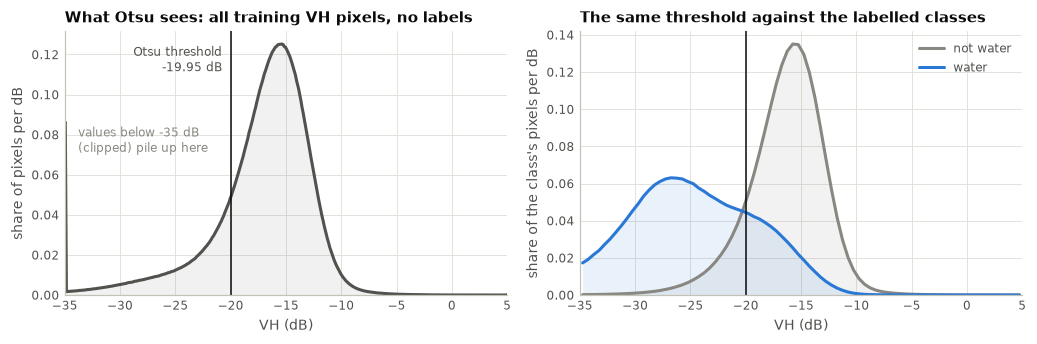

In [4]:
hist = pd.read_csv(ROOT / "results" / "db_histograms.csv")
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2))
axes[0].plot(centers, counts / counts.sum() / 0.1, color=viz.INK_2)
axes[0].fill_between(centers, counts / counts.sum() / 0.1, color=viz.INK_2, alpha=0.08, linewidth=0)
axes[0].axvline(threshold, color=viz.INK, linewidth=1)
axes[0].annotate(f"Otsu threshold\n{threshold:.2f} dB", (threshold, axes[0].get_ylim()[1] * 0.95), xytext=(-6, 0),
                 textcoords="offset points", ha="right", va="top", fontsize=8, color=viz.INK_2)
axes[0].annotate("values below -35 dB\n(clipped) pile up here", (-34.9, counts[0] / counts.sum() / 0.1), xytext=(8, -2),
                 textcoords="offset points", va="top", fontsize=8, color=viz.MUTED)
axes[0].set_title("What Otsu sees: all training VH pixels, no labels")
axes[0].set_xlabel("VH (dB)")
axes[0].set_ylabel("share of pixels per dB")
axes[0].set_xlim(-35, 5)
axes[0].set_ylim(bottom=0)

for cname, color, label in (("not_water", viz.GREY, "not water"), ("water", viz.BLUE, "water")):
    h = hist[(hist["band"] == "VH") & (hist["class"] == cname)]
    inside = h[np.isfinite(h["bin_left"]) & np.isfinite(h["bin_right"])]
    x = (inside["bin_left"] + inside["bin_right"]) / 2
    y = inside["count"] / h["count"].sum() / 0.5
    axes[1].plot(x, y, color=color, label=label)
    axes[1].fill_between(x, y, color=color, alpha=0.10, linewidth=0)
axes[1].axvline(threshold, color=viz.INK, linewidth=1)
axes[1].set_title("The same threshold against the labelled classes")
axes[1].set_xlabel("VH (dB)")
axes[1].set_ylabel("share of the class's pixels per dB")
axes[1].set_xlim(-35, 5)
axes[1].set_ylim(bottom=0)
axes[1].legend(loc="upper right")
fig.tight_layout()
viz.savefig(fig, ROOT / "figures" / "otsu_threshold.png")
plt.show()

The pooled histogram has one dominant hump (land) and a long dark shoulder (water). Otsu puts the cut at about −20 dB. Against the labels (right) the cut sits where the two class curves cross, so it is a reasonable threshold; but a good part of the water lies to its right (missed) and the dark tail of the land lies to its left (false alarms).

## 3. How far can *any* single VH threshold go? (training and validation only)

Purely as a diagnostic, the rule "water where VH < t" is scored for every t. This uses labels, so it is not Otsu's method; it shows the ceiling of thresholding as a method.

In [5]:
ts = otsu_baseline.SWEEP
sweep = pd.DataFrame({"threshold_db": ts,
                      "train_iou": otsu_baseline.threshold_sweep("train", ts),
                      "val_iou": otsu_baseline.threshold_sweep("val", ts)})
sweep.to_csv(ROOT / "results" / "R00_threshold_sweep.csv", index=False)

tuned = otsu_baseline.tuned_threshold()
at = lambda t: sweep.iloc[(sweep["threshold_db"] - t).abs().idxmin()]
ceiling = pd.DataFrame({
    "threshold (dB)": [threshold, tuned],
    "training IoU": [at(threshold)["train_iou"], at(tuned)["train_iou"]],
    "validation IoU": [at(threshold)["val_iou"], at(tuned)["val_iou"]],
}, index=["Otsu (no labels)", "best threshold on the training labels"])
ceiling

,threshold (dB),training IoU,validation IoU
Otsu (no labels),-19.9500,0.3463,0.3880
best threshold on the training labels,-23.6000,0.4653,0.4920


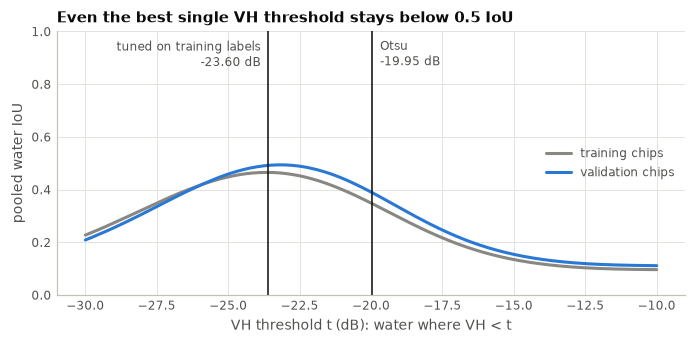

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(sweep["threshold_db"], sweep["train_iou"], color=viz.GREY, label="training chips")
ax.plot(sweep["threshold_db"], sweep["val_iou"], color=viz.BLUE, label="validation chips")
for t, name, ha, dx in ((threshold, f"Otsu\n{threshold:.2f} dB", "left", 5), (tuned, f"tuned on training labels\n{tuned:.2f} dB", "right", -5)):
    ax.axvline(t, color=viz.INK, linewidth=1)
    ax.annotate(name, (t, 0.97), xytext=(dx, 0), textcoords="offset points", ha=ha, va="top", fontsize=8, color=viz.INK_2)
ax.set_xlabel("VH threshold t (dB): water where VH < t")
ax.set_ylabel("pooled water IoU")
ax.set_ylim(0, 1)
ax.set_title("Even the best single VH threshold stays below 0.5 IoU")
ax.legend(loc="center right")
fig.tight_layout()
viz.savefig(fig, ROOT / "figures" / "otsu_threshold_sweep.png")
plt.show()

Two things follow.

* **Otsu is not the best threshold.** Its cut at about −20 dB lets in too much dark land. A threshold chosen with the training labels sits lower, near −23.6 dB, and is clearly better on validation (IoU about 0.49 against 0.39).
* **Thresholding itself has a low ceiling.** Even that best-possible threshold stays below 0.5 IoU. The limit is the method (one number per pixel, no context), not the choice of the number.

Otsu stays the baseline of experiment E0, exactly as planned (run **R00**). Because a baseline that is easy to beat proves little, the label-tuned threshold is scored as well, as an extra reference (run **R00b**, not in the original plan). It is fitted on training labels only, so scoring it on test is legitimate, and it can only make the comparison harder for the U-Nets.

## 4. Score the two threshold rules

Both thresholds are now fixed. Each rule is scored on validation (for later comparisons that must not touch test), and **once** on test and on Bolivia.

In [7]:
r00, r00b = otsu_baseline.main()

Otsu threshold on the training VH pixels: -19.95 dB


R00 val      IoU 0.3880  P 0.4265  R 0.8110  F1 0.5591  mean per-chip IoU 0.2642 (86 chips, 3 skipped)


R00 test     IoU 0.4334  P 0.4827  R 0.8094  F1 0.6047  mean per-chip IoU 0.2604 (89 chips, 1 skipped)


R00 bolivia  IoU 0.6529  P 0.7310  R 0.8594  F1 0.7900  mean per-chip IoU 0.4423 (15 chips, 0 skipped)



Threshold with the best pooled IoU on the training labels: -23.60 dB


R00b val      IoU 0.4920  P 0.7076  R 0.6175  F1 0.6595  mean per-chip IoU 0.2784 (86 chips, 3 skipped)


R00b test     IoU 0.5240  P 0.7468  R 0.6371  F1 0.6876  mean per-chip IoU 0.2789 (89 chips, 1 skipped)


R00b bolivia  IoU 0.5314  P 0.8700  R 0.5773  F1 0.6940  mean per-chip IoU 0.3223 (15 chips, 0 skipped)


In [8]:
rows = {}
for name, metrics in (("R00 Otsu", r00), ("R00b tuned threshold", r00b)):
    for split in ("val", "test", "bolivia"):
        m = metrics[split]
        rows[(name, split)] = {"threshold (dB)": metrics["threshold_db"], "water IoU (pooled)": m["iou"],
                               "precision": m["precision"], "recall": m["recall"], "F1": m["f1"],
                               "mean per-chip IoU": m["mean_chip_iou"], "chips in the mean": m["chips_in_mean"],
                               "IoU without no-radar pixels": m["observed_only"]["iou"]}
pd.DataFrame(rows).T

threshold (dB)  water IoU (pooled)  precision  \
R00 Otsu             val            -19.9500              0.3880     0.4265   
                     test           -19.9500              0.4334     0.4827   
                     bolivia        -19.9500              0.6529     0.7310   
R00b tuned threshold val            -23.6000              0.4920     0.7076   
                     test           -23.6000              0.5240     0.7468   
                     bolivia        -23.6000              0.5314     0.8700   

                              recall     F1  mean per-chip IoU  \
R00 Otsu             val      0.8110 0.5591             0.2642   
                     test     0.8094 0.6047             0.2604   
                     bolivia  0.8594 0.7900             0.4423   
R00b tuned threshold val      0.6175 0.6595             0.2784   
                     test     0.6371 0.6876             0.2789   
                     bolivia  0.5773 0.6940             0.3223   

                              chips in the mean  IoU without no-radar pixels  
R00 Otsu             val                86.0000                       0.3885  
                     test               89.0000                       0.4381  
                     bolivia            15.0000                       0.6562  
R00b tuned threshold val                86.0000                       0.4931  
                     test               89.0000                       0.5327  
                     bolivia            15.0000                       0.5346

**Reading the baselines.**

* **Test, Otsu (R00).** The threshold finds most of the water (recall 0.81) but about half of what it flags is not water (precision 0.48): dark land is the weak point of thresholding. Pooled IoU 0.43.
* **Test, tuned threshold (R00b).** The lower cut trades recall for precision (0.64 and 0.75) and gains about nine IoU points (0.52).
* **Bolivia flips the ranking.** On the held-out flood the tuned threshold misses over 40% of the water (recall 0.58) and falls *below* Otsu (IoU 0.53 against 0.65). A cut fitted to ten floods does not carry over to an eleventh; much of Bolivia's water lies between the two thresholds.
* **Per chip, both rules are poor.** The mean per-chip IoU is 0.26 to 0.28 on test, far below the pooled IoU: the pooled number is carried by a few chips with a lot of open water, and on the many chips with little water a handful of false alarms ruins the chip's score.
* One test chip has labels but no radar data. Leaving out the pixels that have a label but no radar value raises the test IoU by less than one point for both rules (last column).

These are the numbers a U-Net has to beat. They are stored in `results/R00/` and `results/R00b/` in the same format as every later run.